# Energy Analyst Programming Exercise — working notebook
Work happens here first; approved code is exported to `main.py`.

## Parameters
System-specific parameters (file paths, packages). Update these to run on another machine.

In [1]:
# Required packages: pandas, numpy, matplotlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd()                          # repo root (main.py uses its own folder)
DATA_DIR = BASE_DIR / "historicalPriceData"   # historical power price data
OUTPUT_DIR = BASE_DIR / "output"              # all generated CSVs and images
OUTPUT_DIR.mkdir(exist_ok=True)

## Task 1 — Read and combine all historical data files

In [2]:
# Read every yearly price file and stack them into one dataframe
files = sorted(DATA_DIR.glob("*.csv"))
prices = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

# Parse timestamps so we can group by year/month and sort by hour later
prices["Date"] = pd.to_datetime(prices["Date"])

# Quick checks
print("Files read:", [f.name for f in files])
print("Rows:", len(prices))
print("Date range:", prices["Date"].min(), "to", prices["Date"].max())
print("Settlement points:", prices["SettlementPoint"].nunique())
print(sorted(prices["SettlementPoint"].unique()))
print("Missing prices:", prices["Price"].isna().sum())
prices.head()

Files read: ['ERCOT_DA_Prices_2016.csv', 'ERCOT_DA_Prices_2017.csv', 'ERCOT_DA_Prices_2018.csv', 'ERCOT_DA_Prices_2019.csv']
Rows: 497320
Date range: 2016-01-01 00:00:00 to 2019-12-31 23:00:00
Settlement points: 15
['HB_BUSAVG', 'HB_HOUSTON', 'HB_HUBAVG', 'HB_NORTH', 'HB_PAN', 'HB_SOUTH', 'HB_WEST', 'LZ_AEN', 'LZ_CPS', 'LZ_HOUSTON', 'LZ_LCRA', 'LZ_NORTH', 'LZ_RAYBN', 'LZ_SOUTH', 'LZ_WEST']
Missing prices: 0


,Date,SettlementPoint,Price
0,2016-01-01,HB_BUSAVG,18.42
1,2016-01-01,HB_HOUSTON,18.42
2,2016-01-01,HB_HUBAVG,18.42
3,2016-01-01,HB_NORTH,18.43
4,2016-01-01,HB_SOUTH,18.38


## Task 2 — Monthly average price per settlement point (Jan 2016–Dec 2019, keep prices ≤ 0)

In [3]:
# Add Year and Month columns from the hourly timestamp
prices["Year"] = prices["Date"].dt.year
prices["Month"] = prices["Date"].dt.month

# Average price per settlement point per year-month.
# Prices <= 0 are kept on purpose: negative prices are real in deregulated markets.
# Result: 681 rows, not 15 x 48 = 720. HB_PAN only has data from 2019-04-06,
# so it has 9 year-months (Apr-Dec 2019); April 2019 is a partial month (600 hours).
monthly_avg = (
    prices.groupby(["SettlementPoint", "Year", "Month"], as_index=False)["Price"]
    .mean()
    .rename(columns={"Price": "AveragePrice"})
)

# Quick checks
print("Rows:", len(monthly_avg))
print("Year-months per settlement point:")
print(monthly_avg.groupby("SettlementPoint").size().to_string())
print("Lowest monthly average:\n", monthly_avg.nsmallest(1, "AveragePrice").to_string(index=False))
print("Highest monthly average:\n", monthly_avg.nlargest(1, "AveragePrice").to_string(index=False))
monthly_avg.head()

Rows: 681
Year-months per settlement point:
SettlementPoint
HB_BUSAVG     48
HB_HOUSTON    48
HB_HUBAVG     48
HB_NORTH      48
HB_PAN         9
HB_SOUTH      48
HB_WEST       48
LZ_AEN        48
LZ_CPS        48
LZ_HOUSTON    48
LZ_LCRA       48
LZ_NORTH      48
LZ_RAYBN      48
LZ_SOUTH      48
LZ_WEST       48
Lowest monthly average:
 SettlementPoint  Year  Month  AveragePrice
         HB_PAN  2019     12      8.817245
Highest monthly average:
 SettlementPoint  Year  Month  AveragePrice
        LZ_WEST  2019      8    128.876465


,SettlementPoint,Year,Month,AveragePrice
0,HB_BUSAVG,2016,1,19.209301
1,HB_BUSAVG,2016,2,15.288247
2,HB_BUSAVG,2016,3,16.755626
3,HB_BUSAVG,2016,4,18.289347
4,HB_BUSAVG,2016,5,18.159583


In [4]:
# Second average: one price per year-month across ALL settlement points (48 rows).
# Uses every hourly price from every point in that month, so it weights by hours of data.
# Note: HB_PAN joins from April 2019, so from then on 15 points feed the average instead of 14.
monthly_avg_all_points = (
    prices.groupby(["Year", "Month"], as_index=False)["Price"]
    .mean()
    .rename(columns={"Price": "AveragePrice"})
)

# Quick checks
print("Rows:", len(monthly_avg_all_points))
print("Lowest:\n", monthly_avg_all_points.nsmallest(1, "AveragePrice").to_string(index=False))
print("Highest:\n", monthly_avg_all_points.nlargest(1, "AveragePrice").to_string(index=False))
# Compare with the simple mean of the per-point monthly averages
alt = monthly_avg.groupby(["Year", "Month"])["AveragePrice"].mean().values
print("Max difference vs mean of per-point averages:", abs(monthly_avg_all_points["AveragePrice"].values - alt).max())
monthly_avg_all_points.head()

Rows: 48
Lowest:
  Year  Month  AveragePrice
 2016      2     15.387485
Highest:
  Year  Month  AveragePrice
 2019      8     126.67975
Max difference vs mean of per-point averages: 0.07176926966292285


,Year,Month,AveragePrice
0,2016,1,19.335748
1,2016,2,15.387485
2,2016,3,16.991993
3,2016,4,18.557516
4,2016,5,18.501367


## Task 3 — Write AveragePriceByMonth.csv (SettlementPoint, Year, Month, AveragePrice)

In [5]:
# Write the per-settlement-point monthly averages (exactly the 4 required columns, no index)
monthly_avg[["SettlementPoint", "Year", "Month", "AveragePrice"]].to_csv(
    OUTPUT_DIR / "AveragePriceByMonth.csv", index=False
)

# Quick checks
check = pd.read_csv(OUTPUT_DIR / "AveragePriceByMonth.csv")
print("Columns:", list(check.columns))
print("Rows:", len(check))
print(check.head(3).to_string(index=False))

Columns: ['SettlementPoint', 'Year', 'Month', 'AveragePrice']
Rows: 681
SettlementPoint  Year  Month  AveragePrice
      HB_BUSAVG  2016      1     19.209301
      HB_BUSAVG  2016      2     15.288247
      HB_BUSAVG  2016      3     16.755626


## Task 4 — Hourly volatility per year, hubs (HB_) only, set prices ≤ 0 to NaN before log returns

In [6]:
# Hubs only (prefix HB_); load zones are excluded by the task
hubs = prices[prices["SettlementPoint"].str.startswith("HB_")].copy()

# Sort each hub's prices in time order before taking returns
hubs = hubs.sort_values(["SettlementPoint", "Date"])

# Filter out prices <= 0 (log is only defined for positive values).
# Set them to NaN instead of dropping the rows, so no return is computed across
# the gap (a multi-hour change would otherwise be reported as a 1-hour return).
hubs["Price"] = hubs["Price"].where(hubs["Price"] > 0)

# Hourly log return = ln(P_t) - ln(P_t-1), computed within each hub and year
# (groupby keeps returns from crossing hubs or year boundaries).
# Returns into or out of a NaN hour are NaN and are skipped by std().
hubs["LogReturn"] = hubs.groupby(["SettlementPoint", "Year"])["Price"].transform(
    lambda p: np.log(p).diff()
)

# Hourly volatility = standard deviation of log returns (sample std, ddof=1)
hourly_vol = (
    hubs.groupby(["SettlementPoint", "Year"], as_index=False)["LogReturn"]
    .std()
    .rename(columns={"LogReturn": "HourlyVolatility"})
)

# Quick checks
print("Rows:", len(hourly_vol), "(HB_PAN only has 2019)")
print("Prices set to NaN:", hubs["Price"].isna().sum())
print(hourly_vol.pivot(index="SettlementPoint", columns="Year", values="HourlyVolatility").round(6).to_string())

Rows: 25 (HB_PAN only has 2019)
Prices set to NaN: 1024
Year                 2016      2017      2018      2019
SettlementPoint                                        
HB_BUSAVG        0.185773  0.154092  0.200254  0.249378
HB_HOUSTON       0.191099  0.170477  0.200244  0.247946
HB_HUBAVG        0.187957  0.158687  0.202121  0.250648
HB_NORTH         0.184181  0.152575  0.200159  0.249618
HB_PAN                NaN       NaN       NaN  0.547431
HB_SOUTH         0.208533  0.156145  0.198684  0.248980
HB_WEST          0.206858  0.239376  0.287354  0.325545


## Task 5 — Write HourlyVolatilityByYear.csv (SettlementPoint, Year, HourlyVolatility)

In [7]:
# Write hourly volatilities (exact, case-sensitive column names, no index)
hourly_vol[["SettlementPoint", "Year", "HourlyVolatility"]].to_csv(
    OUTPUT_DIR / "HourlyVolatilityByYear.csv", index=False
)

# Quick checks
check = pd.read_csv(OUTPUT_DIR / "HourlyVolatilityByYear.csv")
print("Columns:", list(check.columns))
print("Rows:", len(check), "| Missing:", check.isna().sum().sum())
print(check.head(3).to_string(index=False))

Columns: ['SettlementPoint', 'Year', 'HourlyVolatility']
Rows: 25 | Missing: 0
SettlementPoint  Year  HourlyVolatility
      HB_BUSAVG  2016          0.185773
      HB_BUSAVG  2017          0.154092
      HB_BUSAVG  2018          0.200254


## Task 6 — Highest-volatility hub per year → MaxVolatilityByYear.csv

In [8]:
# For each year, keep the hub row with the highest hourly volatility
# (compared at full precision, so close calls like 2016 are not rounded into a tie)
max_vol = hourly_vol.loc[hourly_vol.groupby("Year")["HourlyVolatility"].idxmax()]

# Same columns as Task 5
max_vol[["SettlementPoint", "Year", "HourlyVolatility"]].to_csv(
    OUTPUT_DIR / "MaxVolatilityByYear.csv", index=False
)

# Quick checks
print(pd.read_csv(OUTPUT_DIR / "MaxVolatilityByYear.csv").to_string(index=False))

SettlementPoint  Year  HourlyVolatility
       HB_SOUTH  2016          0.208533
        HB_WEST  2017          0.239376
        HB_WEST  2018          0.287354
         HB_PAN  2019          0.547431


## Task 7 — Model-ready files: output/formattedSpotHistory/spot_<SettlementPoint>.csv (15 files)

In [9]:
# Model-ready format (see supplementalMaterials): one row per day,
# columns Variable, Date, X1..X24. Data is hour-beginning, so hour 00:00 -> X1, 23:00 -> X24.
SPOT_DIR = OUTPUT_DIR / "formattedSpotHistory"
SPOT_DIR.mkdir(exist_ok=True)

spot = prices[["SettlementPoint", "Date", "Price"]].copy()
spot["Day"] = spot["Date"].dt.strftime("%Y-%m-%d")
spot["HourCol"] = "X" + (spot["Date"].dt.hour + 1).astype(str)
hour_cols = [f"X{h}" for h in range(1, 25)]

for point, data in spot.groupby("SettlementPoint"):
    # One row per day, one column per hour; reindex keeps all 24 columns in order
    wide = data.pivot(index="Day", columns="HourCol", values="Price").reindex(columns=hour_cols)
    wide.insert(0, "Variable", point)
    wide = wide.reset_index().rename(columns={"Day": "Date"})
    wide = wide[["Variable", "Date"] + hour_cols]
    # Missing hours (DST spring-forward 02:00) are written as "NA", like the examples
    wide.to_csv(SPOT_DIR / f"spot_{point}.csv", index=False, na_rep="NA")

# Quick checks
files = sorted(SPOT_DIR.glob("spot_*.csv"))
print("Files:", len(files))
for f in files:
    df = pd.read_csv(f)
    print(f.name, "rows:", len(df), "| NA cells:", df[hour_cols].isna().sum().sum())
print(pd.read_csv(SPOT_DIR / "spot_HB_NORTH.csv").iloc[[0, 72], :7].to_string(index=False))

Files: 15
spot_HB_BUSAVG.csv rows: 1461 | NA cells: 4
spot_HB_HOUSTON.csv rows: 1461 | NA cells: 4
spot_HB_HUBAVG.csv rows: 1461 | NA cells: 4
spot_HB_NORTH.csv rows: 1461 | NA cells: 4
spot_HB_PAN.csv rows: 270 | NA cells: 0
spot_HB_SOUTH.csv rows: 1461 | NA cells: 4
spot_HB_WEST.csv rows: 1461 | NA cells: 4
spot_LZ_AEN.csv rows: 1461 | NA cells: 4
spot_LZ_CPS.csv rows: 1461 | NA cells: 4
spot_LZ_HOUSTON.csv rows: 1461 | NA cells: 4
spot_LZ_LCRA.csv rows: 1461 | NA cells: 4
spot_LZ_NORTH.csv rows: 1461 | NA cells: 4
spot_LZ_RAYBN.csv rows: 1461 | NA cells: 4
spot_LZ_SOUTH.csv rows: 1461 | NA cells: 4
spot_LZ_WEST.csv rows: 1461 | NA cells: 4
Variable       Date    X1    X2    X3    X4    X5
HB_NORTH 2016-01-01 18.43 16.17 15.64 15.65 15.97
HB_NORTH 2016-03-13 11.70  8.00   NaN  6.05  5.76


## Bonus — Mean plots: SettlementHubAveragePriceByMonth.png, LoadZoneAveragePriceByMonth.png

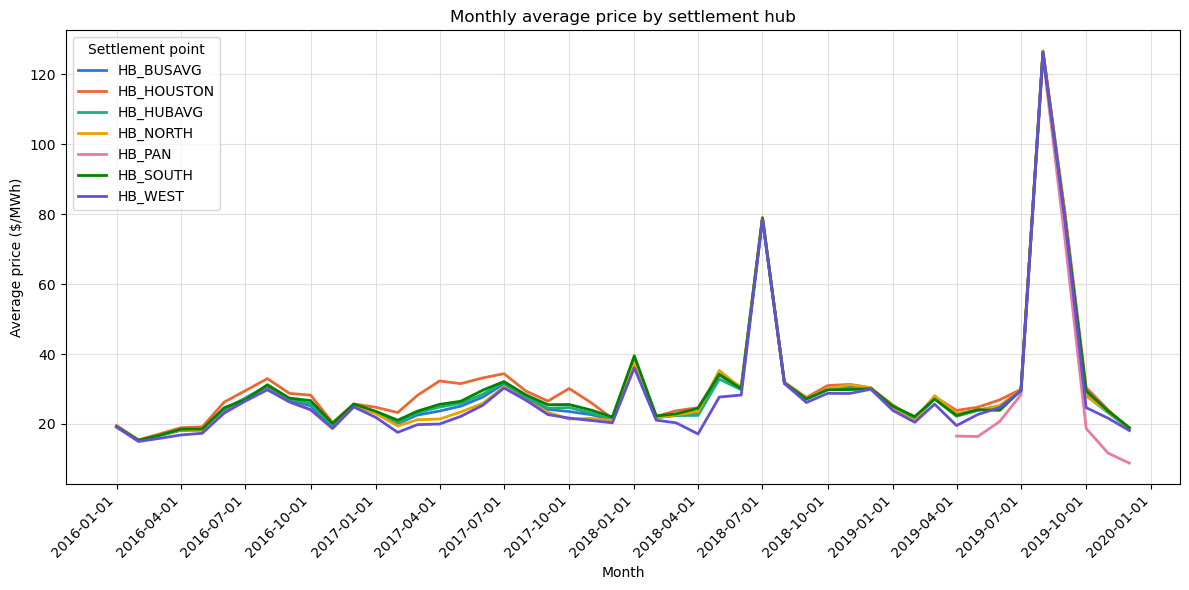

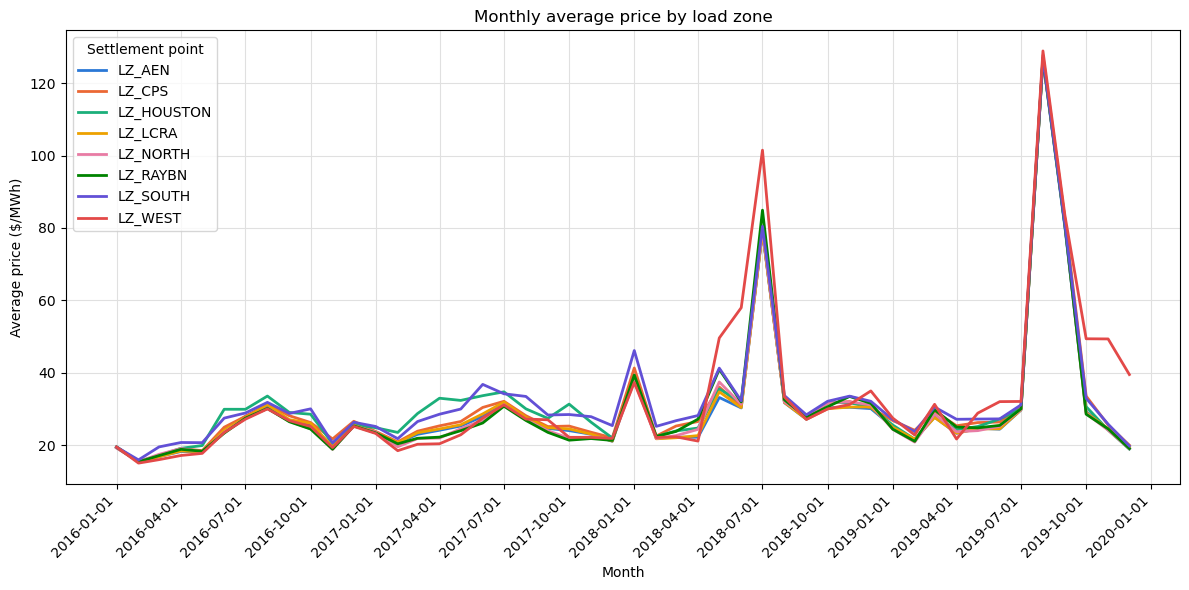

['LoadZoneAveragePriceByMonth.png', 'SettlementHubAveragePriceByMonth.png']


In [10]:
import matplotlib.dates as mdates

# Date column for the x-axis: first day of each month keeps months in chronological order
monthly_avg["MonthStart"] = pd.to_datetime(dict(year=monthly_avg["Year"], month=monthly_avg["Month"], day=1))

# Eight distinct colors, assigned in a fixed order (one per settlement point)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]


def plot_monthly_avg(prefix, title, filename):
    """Overlay one line per settlement point with the given prefix and save as PNG."""
    data = monthly_avg[monthly_avg["SettlementPoint"].str.startswith(prefix)]
    fig, ax = plt.subplots(figsize=(12, 6))
    for color, (point, d) in zip(COLORS, data.groupby("SettlementPoint")):
        ax.plot(d["MonthStart"], d["AveragePrice"], color=color, linewidth=2, label=point)
    ax.set_title(title)
    ax.set_xlabel("Month")
    ax.set_ylabel("Average price ($/MWh)")
    # Tick every 3 months, labelled as YYYY-MM-DD (first day of the month)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.grid(True, color="#e0e0e0", linewidth=0.8)
    ax.legend(title="Settlement point", loc="upper left")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=150)
    plt.show()


plot_monthly_avg("HB_", "Monthly average price by settlement hub", "SettlementHubAveragePriceByMonth.png")
plot_monthly_avg("LZ_", "Monthly average price by load zone", "LoadZoneAveragePriceByMonth.png")

# Quick checks
print([f.name for f in OUTPUT_DIR.glob("*AveragePriceByMonth.png")])

## Bonus — Volatility plots

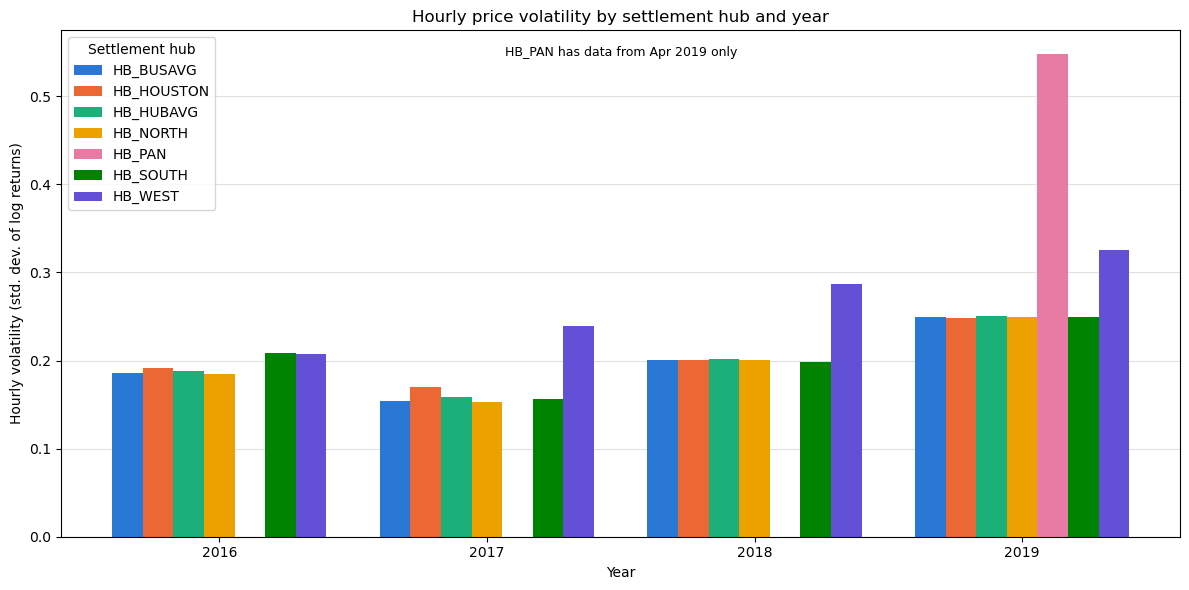

['HourlyVolatilityByHubBars.png']


In [11]:
# Hub -> color, same assignment as the hub mean plot (sorted hub names, fixed color order)
hub_names = sorted(hourly_vol["SettlementPoint"].unique())
HUB_COLORS = dict(zip(hub_names, COLORS))
vol_wide = hourly_vol.pivot(index="Year", columns="SettlementPoint", values="HourlyVolatility")
years = vol_wide.index.tolist()

# Grouped bars - compare hubs within each year (tallest bar = Task 6 winner)
fig, ax = plt.subplots(figsize=(12, 6))
bar_width = 0.8 / len(hub_names)
for k, hub in enumerate(hub_names):
    x = [y + (k - (len(hub_names) - 1) / 2) * bar_width for y in years]
    ax.bar(x, vol_wide[hub], width=bar_width, color=HUB_COLORS[hub], label=hub)
ax.set_xticks(years)
ax.set_title("Hourly price volatility by settlement hub and year")
ax.set_xlabel("Year")
ax.set_ylabel("Hourly volatility (std. dev. of log returns)")
ax.grid(True, axis="y", color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(title="Settlement hub", loc="upper left")
ax.text(0.5, 0.97, "HB_PAN has data from Apr 2019 only", transform=ax.transAxes, ha="center", va="top", fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "HourlyVolatilityByHubBars.png", dpi=150)
plt.show()

# Quick checks
print([f.name for f in OUTPUT_DIR.glob("HourlyVolatilityByHub*.png")])

## Bonus — Hourly shape profiles: output/hourlyShapeProfiles/profile_<SettlementPoint>.csv (15 files)

In [12]:
# Hourly shape profile: the 24 average hourly prices for one month-of-year and
# day-of-week, divided by their own mean so the 24 values average exactly 1.
PROFILE_DIR = OUTPUT_DIR / "hourlyShapeProfiles"
PROFILE_DIR.mkdir(exist_ok=True)

shape = prices[["SettlementPoint", "Date", "Price"]].copy()
shape["Month"] = shape["Date"].dt.month
shape["DayOfWeek"] = shape["Date"].dt.dayofweek + 1   # 1 = Monday ... 7 = Sunday
shape["Hour"] = shape["Date"].dt.hour + 1             # hour-beginning: 00:00 -> hour 1

# Average price for each point, month, day of week and hour (all years pooled)
avg = shape.groupby(["SettlementPoint", "Month", "DayOfWeek", "Hour"])["Price"].mean()

# Wide layout: one row per (point, month, day of week), columns X1..X24
profiles = avg.unstack("Hour")
profiles.columns = [f"X{h}" for h in profiles.columns]

# Normalize: divide each row by its own 24-hour mean
# Caveat: HB_PAN (data from Apr 2019 only, so 63 profiles instead of 84) has frequent
# negative prices. Some of its 24-hour means are near zero or negative (Dec-Thursday = -0.75),
# so dividing flips signs and gives extreme values (-11 to +16). These profiles still average
# exactly 1 but are not reliable shapes; all other points range about 0.22-5.9.
profiles = profiles.div(profiles.mean(axis=1), axis=0)

for point, p in profiles.groupby(level="SettlementPoint"):
    p.reset_index().to_csv(PROFILE_DIR / f"profile_{point}.csv", index=False)

# Quick checks
files = sorted(PROFILE_DIR.glob("profile_*.csv"))
print("Files:", len(files))
row_means = profiles.mean(axis=1)
print("Profiles per point:", profiles.groupby(level="SettlementPoint").size().unique())
print("Max |row mean - 1|:", (row_means - 1).abs().max())
print("Value range by point:")
print(profiles.stack().groupby(level="SettlementPoint").agg(["min", "max"]).round(2).to_string())
print(pd.read_csv(PROFILE_DIR / "profile_HB_NORTH.csv").iloc[:2, :8].to_string(index=False))

Files: 15
Profiles per point: [84 63]
Max |row mean - 1|: 3.3306690738754696e-16
Value range by point:
                   min    max
SettlementPoint              
HB_BUSAVG         0.22   5.91
HB_HOUSTON        0.22   5.88
HB_HUBAVG         0.22   5.91
HB_NORTH          0.22   5.92
HB_PAN          -11.04  16.41
HB_SOUTH          0.23   5.90
HB_WEST           0.22   5.93
LZ_AEN            0.23   5.90
LZ_CPS            0.23   5.88
LZ_HOUSTON        0.22   5.88
LZ_LCRA           0.22   5.90
LZ_NORTH          0.22   5.91
LZ_RAYBN          0.22   5.91
LZ_SOUTH          0.23   5.70
LZ_WEST           0.22   5.83
SettlementPoint  Month  DayOfWeek       X1       X2       X3       X4       X5
       HB_NORTH      1          1 0.766772 0.737967 0.735063 0.756690 0.821989
       HB_NORTH      1          2 0.642560 0.609833 0.613626 0.647372 0.739023


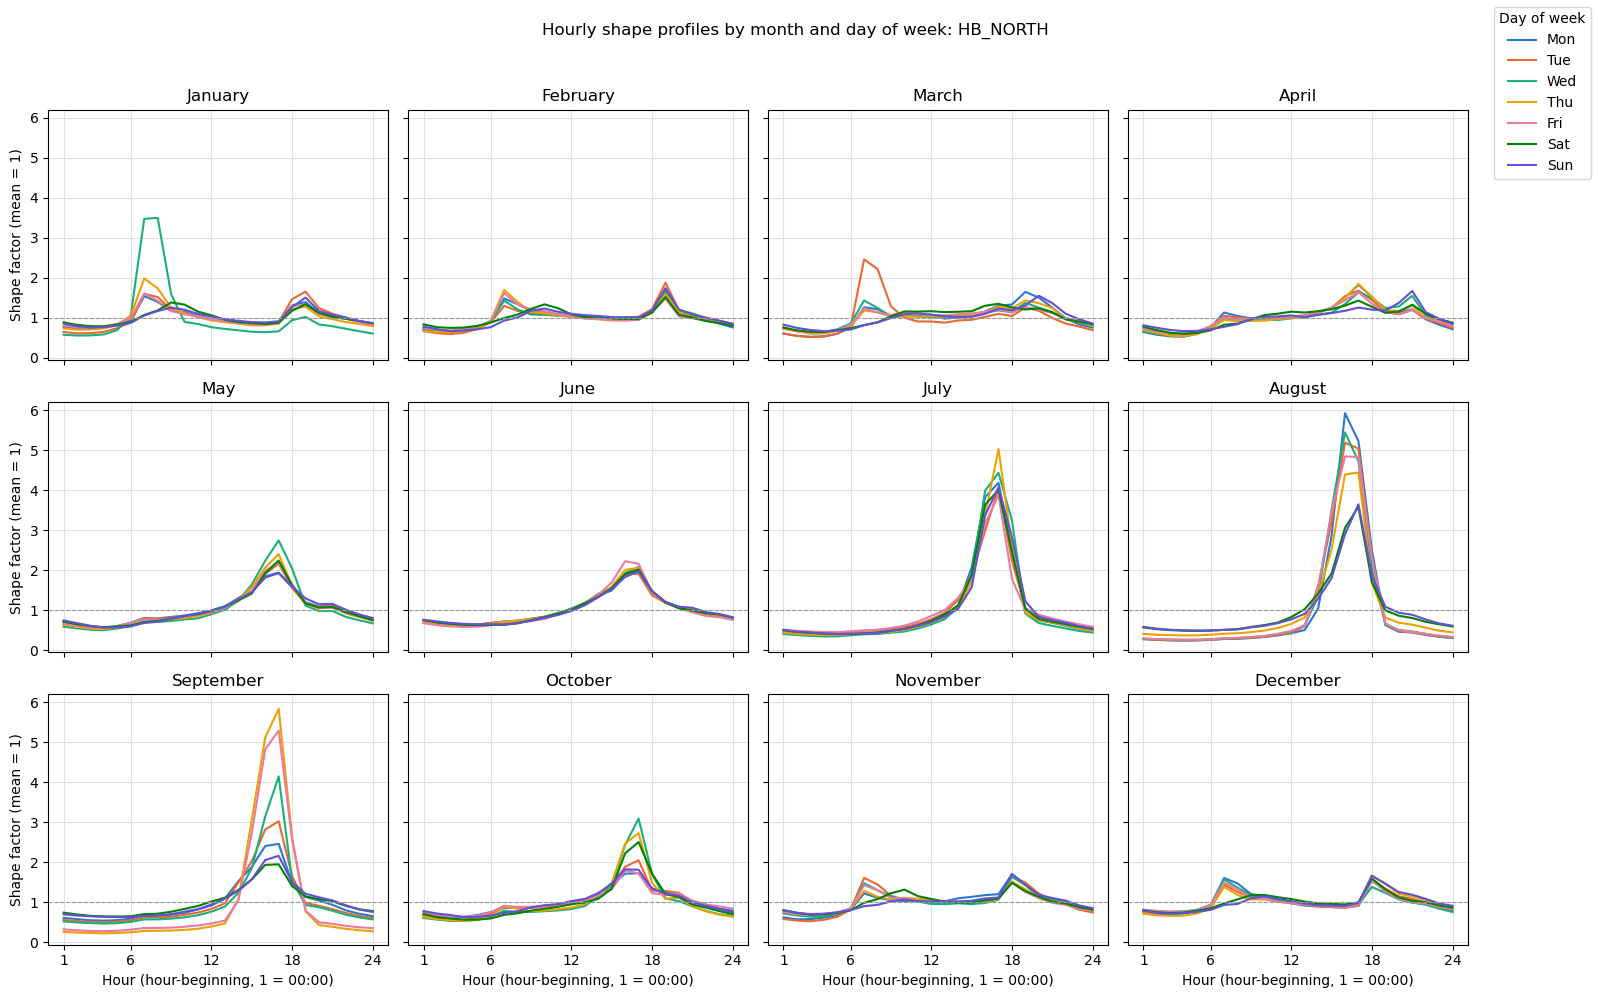

In [13]:
# NOTEBOOK ONLY - visual check of the shape profiles; not exported to main.py, no file saved.
# One panel per month for one settlement point, one line per day of week.
PLOT_POINT = "HB_NORTH"   # change to view another settlement point
DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

p = profiles.loc[PLOT_POINT]
fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, sharey=True)
for month, ax in zip(range(1, 13), axes.flat):
    if month in p.index.get_level_values("Month"):
        for dow, color in zip(range(1, 8), COLORS):
            if (month, dow) in p.index:
                ax.plot(range(1, 25), p.loc[(month, dow)], color=color, linewidth=1.5, label=DAY_NAMES[dow - 1])
    ax.axhline(1, color="#999999", linewidth=0.8, linestyle="--")
    ax.set_title(pd.Timestamp(2000, month, 1).strftime("%B"))
    ax.set_xticks([1, 6, 12, 18, 24])
    ax.grid(True, color="#e0e0e0", linewidth=0.8)
for ax in axes[-1]:
    ax.set_xlabel("Hour (hour-beginning, 1 = 00:00)")
for ax in axes[:, 0]:
    ax.set_ylabel("Shape factor (mean = 1)")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Day of week", loc="upper right")
fig.suptitle(f"Hourly shape profiles by month and day of week: {PLOT_POINT}")
fig.tight_layout(rect=[0, 0, 0.93, 0.96])
plt.show()

## Bonus — Open-ended analysis

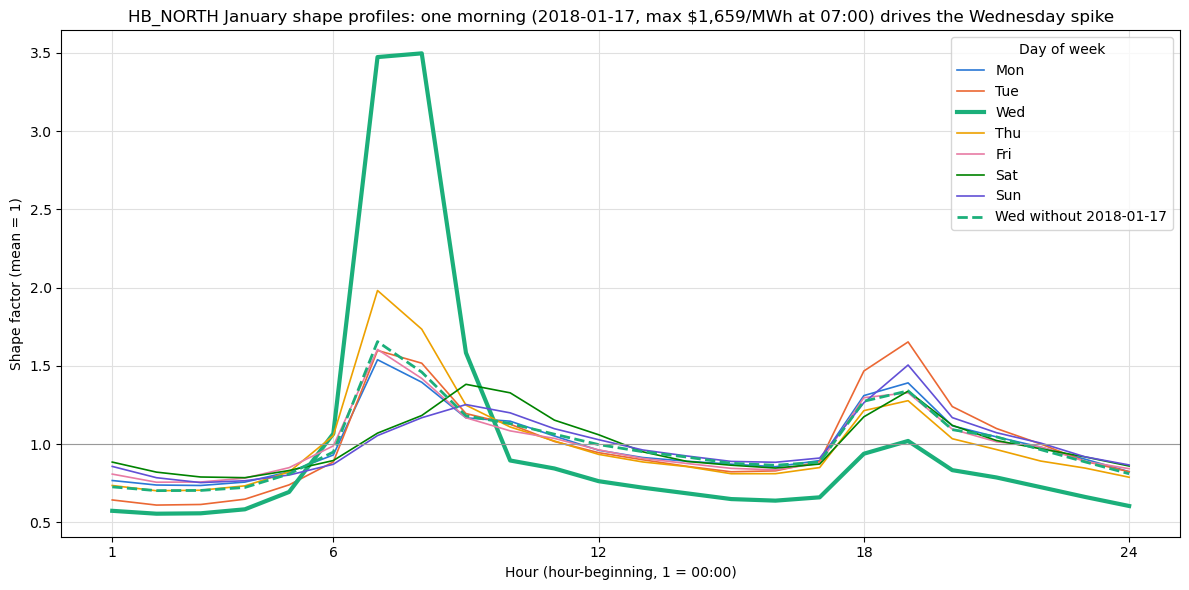

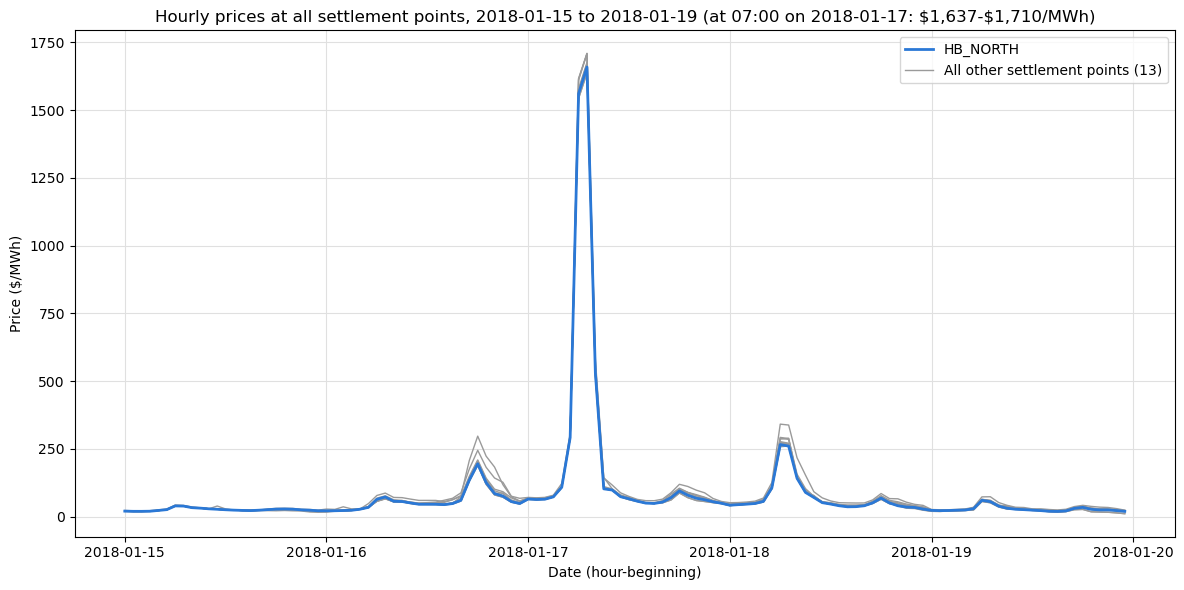

               Date   Price
2018-01-17 07:00:00 1659.26
2018-01-17 06:00:00 1560.79
2018-01-17 08:00:00  529.96


In [14]:
# Open-ended analysis: one extreme morning reshapes a whole hourly shape profile.
#
# Each shape profile averages only ~18 days (one month-of-year x one day-of-week over
# 4 years), so a single scarcity event can dominate it. HB_NORTH, January Wednesday:
#   - On Wed 2018-01-17, prices climbed from ~$73 at 03:00 to $1,561 at 06:00 and
#     $1,659 at 07:00, then fell back to ~$102 by 09:00 (normal January level ~$25-40).
#   - It was system-wide: all 14 settlement points priced $1,637-1,710 at 07:00, so this
#     was a market-wide supply shortage, not local congestion.
#   - It was a multi-day event: HB_NORTH daily averages were ~$26-32 before, $60.5 on
#     01-16, $226.5 on 01-17, $71.7 on 01-18, then back to ~$20-28.
#   - These are the only January hours above $200/MWh in 2016-2019 (01-17 05:00-08:00
#     and 01-18 06:00-07:00), and 07:00 is the 6th-highest HB_NORTH hour of 2016-2018.
#   - Timing (early-morning heating peak in mid-January) is consistent with a cold
#     snap; weather/load data would be needed to confirm the cause.
# Effect: that one morning lifts the January-Wednesday 07:00 shape factor to ~3.5x,
# while the same profile without 2018-01-17 (dashed line) peaks at ~1.6x like the
# other weekdays. Mean-based shapes from short histories mix "typical shape" with rare
# events; a model using them should consider more years, medians, or spike handling.
# A second chart shows hourly prices at all settlement points around the event.
SPIKE_POINT = "HB_NORTH"
SPIKE_MONTH = 1
DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
month_rows = shape[(shape["SettlementPoint"] == SPIKE_POINT) & (shape["Month"] == SPIKE_MONTH)]

# The single highest hourly price in this month identifies the spike day
spike = month_rows.loc[month_rows["Price"].idxmax()]
spike_day, spike_dow = spike["Date"].normalize(), spike["DayOfWeek"]

fig, ax = plt.subplots(figsize=(12, 6))
for dow, color in zip(range(1, 8), COLORS):
    width = 3 if dow == spike_dow else 1.2
    ax.plot(range(1, 25), profiles.loc[(SPIKE_POINT, SPIKE_MONTH, dow)], color=color,
            linewidth=width, label=DAY_NAMES[dow - 1])

# Same day-of-week profile recomputed without the spike day (same normalization)
same_dow = month_rows[month_rows["DayOfWeek"] == spike_dow]
hourly = same_dow[same_dow["Date"].dt.normalize() != spike_day].groupby("Hour")["Price"].mean()
ax.plot(range(1, 25), hourly / hourly.mean(), color=COLORS[spike_dow - 1], linewidth=2,
        linestyle="--", label=f"{DAY_NAMES[spike_dow - 1]} without {spike_day:%Y-%m-%d}")

ax.axhline(1, color="#999999", linewidth=0.8)
ax.set_title(f"{SPIKE_POINT} January shape profiles: one morning ({spike_day:%Y-%m-%d}, "
             f"max ${spike['Price']:,.0f}/MWh at {spike['Date']:%H:%M}) drives the Wednesday spike")
ax.set_xlabel("Hour (hour-beginning, 1 = 00:00)")
ax.set_ylabel("Shape factor (mean = 1)")
ax.set_xticks([1, 6, 12, 18, 24])
ax.grid(True, color="#e0e0e0", linewidth=0.8)
ax.legend(title="Day of week", loc="upper right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ShapeProfileSpike_HB_NORTH_January.png", dpi=150)
plt.show()

# Second chart: hourly prices at every settlement point for the days around the spike.
# The lines lie almost on top of each other, showing the price jump was system-wide.
window = prices[(prices["Date"] >= spike_day - pd.Timedelta(days=2))
                & (prices["Date"] < spike_day + pd.Timedelta(days=3))]
fig, ax = plt.subplots(figsize=(12, 6))
for point, d in window.groupby("SettlementPoint"):
    ax.plot(d["Date"], d["Price"], color="#9a9a9a", linewidth=1)
north = window[window["SettlementPoint"] == SPIKE_POINT]
ax.plot(north["Date"], north["Price"], color=COLORS[0], linewidth=2, label=SPIKE_POINT)
ax.plot([], [], color="#9a9a9a", linewidth=1,
        label=f"All other settlement points ({window['SettlementPoint'].nunique() - 1})")
peak = window[window["Date"] == spike["Date"]]["Price"]
ax.set_title(f"Hourly prices at all settlement points, {spike_day - pd.Timedelta(days=2):%Y-%m-%d} to "
             f"{spike_day + pd.Timedelta(days=2):%Y-%m-%d} (at {spike['Date']:%H:%M} on {spike_day:%Y-%m-%d}: "
             f"\\${peak.min():,.0f}-\\${peak.max():,.0f}/MWh)")  # \\$ = literal dollar sign
ax.set_xlabel("Date (hour-beginning)")
ax.set_ylabel("Price ($/MWh)")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.grid(True, color="#e0e0e0", linewidth=0.8)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "SystemWidePrices_Jan2018.png", dpi=150)
plt.show()

# Quick checks
print(month_rows.nlargest(3, "Price")[["Date", "Price"]].to_string(index=False))